In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

In [2]:
Clean_Data_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data")
Table_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables")
Chart_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts")
Prediction_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\predictions")

print("Clean data:", Clean_Data_Path)
print("Output tables:", Table_Path)
print("Output charts:", Chart_Path)
print("Output charts:", Prediction_Path)

Clean data: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data
Output tables: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables
Output charts: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts
Output charts: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\predictions


In [3]:
orders = pd.read_csv(
    Clean_Data_Path / "orders_clean.csv"
)

order_items = pd.read_csv(
    Clean_Data_Path / "order_items_clean.csv"
)

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

print("Orders:", orders.shape)
print("Order items:", order_items.shape)

Orders: (96461, 8)
Order items: (112650, 7)


In [4]:
# Build order-level features and retain only order IDs present in cleaned orders
order_features = (
    order_items
    .groupby("order_id")
    .agg(
        item_count=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        total_freight=("freight_value", "sum"),
        average_item_price=("price", "mean"),
        maximum_item_price=("price", "max"),
        minimum_item_price=("price", "min")
    )
    .reset_index()
)

order_features = order_features[
    order_features["order_id"].isin(orders["order_id"])
].copy()

# Add order metadata once, using a one-to-one join after aggregation.
order_features = order_features.merge(
    orders[[
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp"
    ]],
    on="order_id",
    how="inner",
    validate="one_to_one"
)

print("Valid order-level rows:", len(order_features))
order_features.head()


Valid order-level rows: 96461


,order_id,item_count,total_revenue,total_freight,average_item_price,maximum_item_price,minimum_item_price,customer_id,order_status,order_purchase_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,58.90,58.90,58.90,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,239.90,239.90,239.90,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,199.00,199.00,199.00,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,12.99,12.99,12.99,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,199.90,199.90,199.90,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51


In [5]:
# Calculate freight as a percentage of item revenue
order_features["freight_to_revenue_percent"] = np.where(
    order_features["total_revenue"] > 0,
    order_features["total_freight"] / order_features["total_revenue"] * 100,
    np.nan
)
order_features.head()


,order_id,item_count,total_revenue,total_freight,average_item_price,maximum_item_price,minimum_item_price,customer_id,order_status,order_purchase_timestamp,freight_to_revenue_percent
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,58.90,58.90,58.90,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,22.563667
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,239.90,239.90,239.90,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,8.307628
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,199.00,199.00,199.00,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,8.979899
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,12.99,12.99,12.99,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,98.460354
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,199.90,199.90,199.90,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,9.074537


In [6]:
# Basic data validation
print("Cleaned order rows:", len(orders))
print("Unique cleaned order IDs:", orders["order_id"].nunique())
print("Order-level anomaly rows:", len(order_features))
print("Unique anomaly order IDs:", order_features["order_id"].nunique())

assert orders["order_id"].is_unique, "Duplicate order IDs found in orders_clean.csv"
assert order_features["order_id"].is_unique, "Duplicate order IDs found in order_features"
assert len(order_features) == orders["order_id"].nunique(), "Some cleaned orders are missing from the anomaly feature table"
assert order_features["order_status"].isna().sum() == 0, "Missing order status after metadata join"
print("Order-count validation PASSED.")

print("\nMissing values:")
print(order_features.isna().sum())

print("\nNegative values:")
print(order_features[["item_count", "total_revenue", "total_freight"]].lt(0).sum())


Cleaned order rows: 96461
Unique cleaned order IDs: 96461
Order-level anomaly rows: 96461
Unique anomaly order IDs: 96461
Order-count validation PASSED.

Missing values:
order_id                      0
item_count                    0
total_revenue                 0
total_freight                 0
average_item_price            0
maximum_item_price            0
minimum_item_price            0
customer_id                   0
order_status                  0
order_purchase_timestamp      0
freight_to_revenue_percent    0
dtype: int64

Negative values:
item_count       0
total_revenue    0
total_freight    0
dtype: int64


In [7]:
#IQR anomaly detection
iqr_features = [
    "total_revenue",
    "total_freight",
    "item_count"
]

iqr_results = order_features[
    ["order_id"] + iqr_features
].copy()

for feature in iqr_features:

    q1 = iqr_results[feature].quantile(0.25)
    q3 = iqr_results[feature].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    iqr_results[f"{feature}_anomaly"] = (
        (iqr_results[feature] < lower_bound)
        |
        (iqr_results[feature] > upper_bound)
    )

    print(
        feature,
        "lower:",
        round(lower_bound, 2),
        "upper:",
        round(upper_bound, 2)
    )

total_revenue lower: -110.1 upper: 305.9
total_freight lower: -1.4 upper: 39.28
item_count lower: 1.0 upper: 1.0


In [8]:
#Overall IQR anomaly flag
anomaly_columns = [
    f"{feature}_anomaly"
    for feature in iqr_features
]

iqr_results["iqr_anomaly"] = (
    iqr_results[anomaly_columns]
    .any(axis=1)
)

iqr_results["iqr_anomaly"].value_counts()

iqr_anomaly
False    76434
True     20027
Name: count, dtype: int64

In [9]:
#IQR anomaly percentage
iqr_anomaly_summary = pd.DataFrame({
    "metric": [
        "Total Orders",
        "IQR Anomalies",
        "IQR Anomaly Rate"
    ],
    "value": [
        len(iqr_results),
        iqr_results["iqr_anomaly"].sum(),
        round(
            iqr_results["iqr_anomaly"].mean() * 100,
            2
        )
    ]
})

iqr_anomaly_summary

,metric,value
0,Total Orders,96461.00
1,IQR Anomalies,20027.00
2,IQR Anomaly Rate,20.76


In [10]:
#Isolation Forest dataset
ml_features = [
    "total_revenue",
    "total_freight",
    "item_count",
    "average_item_price",
    "maximum_item_price",
    "freight_to_revenue_percent"
]

anomaly_data = order_features[
    ["order_id"] + ml_features
].copy()

anomaly_data = anomaly_data.dropna(
    subset=ml_features
).reset_index(drop=True)

print("Rows available for Isolation Forest:", len(anomaly_data))

Rows available for Isolation Forest: 96461


In [11]:
#Handle extreme skew
log_features = [
    "total_revenue",
    "total_freight",
    "average_item_price",
    "maximum_item_price"
]

for feature in log_features:
    anomaly_data[f"log_{feature}"] = np.log1p(
        anomaly_data[feature].clip(lower=0)
    )

In [12]:
#Prepare Isolation Forest features
isolation_features = [
    "log_total_revenue",
    "log_total_freight",
    "item_count",
    "log_average_item_price",
    "log_maximum_item_price",
    "freight_to_revenue_percent"
]

X_anomaly = anomaly_data[
    isolation_features
].copy()

X_anomaly = X_anomaly.replace(
    [np.inf, -np.inf],
    np.nan
)

X_anomaly = X_anomaly.fillna(
    X_anomaly.median()
)

print(X_anomaly.shape)

(96461, 6)


In [13]:
#Standardize features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_anomaly
)

print("Scaled feature matrix:", X_scaled.shape)

Scaled feature matrix: (96461, 6)


In [14]:
#Train Isolation Forest
isolation_model = IsolationForest(
    n_estimators=300,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

isolation_model.fit(
    X_scaled
)

print("Isolation Forest trained.")

Isolation Forest trained.


In [15]:
#Generate anomaly predictions
anomaly_data["isolation_prediction"] = (
    isolation_model.predict(
        X_scaled
    )
)

anomaly_data["anomaly_score"] = (
    isolation_model.decision_function(
        X_scaled
    )
)

anomaly_data["isolation_anomaly"] = (
    anomaly_data["isolation_prediction"] == -1
)

anomaly_data[
    [
        "order_id",
        "isolation_prediction",
        "anomaly_score",
        "isolation_anomaly"
    ]
].head(10)

,order_id,isolation_prediction,anomaly_score,isolation_anomaly
0,00010242fe8c5a6d1ba2dd792cb16214,1,0.260126,False
1,00018f77f2f0320c557190d7a144bdd3,1,0.221222,False
2,000229ec398224ef6ca0657da4fc703e,1,0.242560,False
3,00024acbcdf0a6daa1e931b038114c75,1,0.082393,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,0.241635,False
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,0.195792,False
6,00054e8431b9d7675808bcb819fb4a32,1,0.185923,False
7,000576fe39319847cbb9d288c5617fa6,1,0.034176,False
8,0005a1a1728c9d785b8e2b08b904576c,1,0.234538,False
9,0005f50442cb953dcd1d21e1fb923495,1,0.247739,False


In [16]:
#Isolation Forest summary
isolation_summary = pd.DataFrame({
    "metric": [
        "Orders Analyzed",
        "Isolation Forest Anomalies",
        "Isolation Forest Anomaly Rate"
    ],
    "value": [
        len(anomaly_data),
        anomaly_data["isolation_anomaly"].sum(),
        round(
            anomaly_data["isolation_anomaly"].mean() * 100,
            2
        )
    ]
})

isolation_summary

,metric,value
0,Orders Analyzed,96461.0
1,Isolation Forest Anomalies,1930.0
2,Isolation Forest Anomaly Rate,2.0


In [17]:
#Combine IQR + Isolation Forest
combined_anomalies = anomaly_data[
    [
        "order_id",
        "isolation_anomaly",
        "anomaly_score"
    ]
].merge(
    iqr_results[
        [
            "order_id",
            "iqr_anomaly"
        ]
    ],
    on="order_id",
    how="left"
)

combined_anomalies["anomaly_type"] = np.select(
    [
        (
            combined_anomalies["iqr_anomaly"]
            &
            combined_anomalies["isolation_anomaly"]
        ),

        (
            ~combined_anomalies["iqr_anomaly"]
            &
            combined_anomalies["isolation_anomaly"]
        ),

        (
            combined_anomalies["iqr_anomaly"]
            &
            ~combined_anomalies["isolation_anomaly"]
        )
    ],
    [
        "Strong Anomaly",
        "ML Only",
        "IQR Only"
    ],
    default="Normal"
)

combined_anomalies[
    "anomaly_type"
].value_counts()

anomaly_type
Normal            76020
IQR Only          18511
Strong Anomaly     1516
ML Only             414
Name: count, dtype: int64

In [18]:
#Add business information
anomaly_output = combined_anomalies.merge(
    order_features,
    on="order_id",
    how="left"
)

anomaly_output.head()

,order_id,isolation_anomaly,anomaly_score,iqr_anomaly,anomaly_type,item_count,total_revenue,total_freight,average_item_price,maximum_item_price,minimum_item_price,customer_id,order_status,order_purchase_timestamp,freight_to_revenue_percent
0,00010242fe8c5a6d1ba2dd792cb16214,False,0.260126,False,Normal,1,58.90,13.29,58.90,58.90,58.90,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,22.563667
1,00018f77f2f0320c557190d7a144bdd3,False,0.221222,False,Normal,1,239.90,19.93,239.90,239.90,239.90,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,8.307628
2,000229ec398224ef6ca0657da4fc703e,False,0.242560,False,Normal,1,199.00,17.87,199.00,199.00,199.00,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,8.979899
3,00024acbcdf0a6daa1e931b038114c75,False,0.082393,False,Normal,1,12.99,12.79,12.99,12.99,12.99,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,98.460354
4,00042b26cf59d7ce69dfabb4e55b4fd9,False,0.241635,False,Normal,1,199.90,18.14,199.90,199.90,199.90,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,9.074537


In [19]:
#Highest-risk anomalies
top_anomalies = (
    anomaly_output
    .sort_values(
        "anomaly_score",
        ascending=True
    )
    .head(20)
)

top_anomalies[
    [
        "order_id",
        "order_status",
        "item_count",
        "total_revenue",
        "total_freight",
        "average_item_price",
        "maximum_item_price",
        "freight_to_revenue_percent",
        "anomaly_score",
        "anomaly_type"
    ]
]

,order_id,order_status,item_count,total_revenue,total_freight,average_item_price,maximum_item_price,freight_to_revenue_percent,anomaly_score,anomaly_type
49021,8272b63d03f5f79c56e9e4120aec44ef,delivered,21,31.80,164.37,1.514286,7.80,516.886792,-0.136725,Strong Anomaly
65935,af822dacd6f5cff7376413c03a388bb7,delivered,12,61.26,182.76,5.105000,5.31,298.334966,-0.134831,Strong Anomaly
1432,03caa2c082116e1d31e67e9ae3700499,delivered,8,13440.00,224.08,1680.000000,1680.00,1.667262,-0.133749,Strong Anomaly
56106,95d6357ffe41aa6d2998852a710c70a0,delivered,5,17.50,91.15,3.500000,3.50,520.857143,-0.130399,Strong Anomaly
23848,3f744e5030fb02e02651eb31d5204878,delivered,6,35.40,109.38,5.900000,5.90,308.983051,-0.130245,Strong Anomaly
74039,c471a28c25283860362c67c0a1cd1694,delivered,6,28.68,94.74,4.780000,4.78,330.334728,-0.127787,Strong Anomaly
22841,3caf6c286c8cde37ea9c0fb2da0e3169,delivered,6,47.40,132.36,7.900000,7.90,279.240506,-0.127151,Strong Anomaly
36924,6232b520aa859c47ba46e5213737f418,delivered,5,19.50,76.15,3.900000,3.90,390.512821,-0.123800,Strong Anomaly
87915,e928cc82f61f2dcab3ad58d6e7200224,delivered,6,60.00,124.80,10.000000,10.00,208.000000,-0.120537,Strong Anomaly
30587,50fc570b5b9de1500a9e66edcc9d8525,delivered,6,45.78,90.66,7.630000,7.63,198.034076,-0.116095,Strong Anomaly


In [20]:
#Anomaly type summary
anomaly_type_summary = (
    anomaly_output
    .groupby("anomaly_type")
    .agg(
        orders=("order_id", "nunique"),
        average_revenue=("total_revenue", "mean"),
        average_freight=("total_freight", "mean"),
        average_items=("item_count", "mean"),
        average_freight_ratio=(
            "freight_to_revenue_percent",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        "orders",
        ascending=False
    )
)

anomaly_type_summary

,anomaly_type,orders,average_revenue,average_freight,average_items,average_freight_ratio
2,Normal,76020,87.892747,16.734065,1.000000,30.010024
0,IQR Only,18511,273.303464,41.836252,1.588731,28.237436
3,Strong Anomaly,1516,972.965627,95.366286,2.860818,53.143850
1,ML Only,414,7.977681,16.471932,1.000000,217.848351


In [21]:
anomaly_type_summary.to_csv(
    Table_Path / "anomaly_type_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "anomaly_type_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\anomaly_type_summary.csv


In [22]:
iqr_anomaly_summary.to_csv(
    Table_Path / "iqr_anomaly_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "iqr_anomaly_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\iqr_anomaly_summary.csv


In [23]:
isolation_summary.to_csv(
    Table_Path / "isolation_forest_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "isolation_forest_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\isolation_forest_summary.csv


In [25]:
anomaly_prediction_output = anomaly_output[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "item_count",
        "total_revenue",
        "total_freight",
        "average_item_price",
        "maximum_item_price",
        "freight_to_revenue_percent",
        "iqr_anomaly",
        "isolation_anomaly",
        "anomaly_score",
        "anomaly_type"
    ]
].copy()

anomaly_prediction_output.to_csv(
    Prediction_Path
    / "order_anomaly_predictions.csv",
    index=False
)

print(
    "Saved:",
     Prediction_Path
    / "order_anomaly_predictions.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\predictions\order_anomaly_predictions.csv


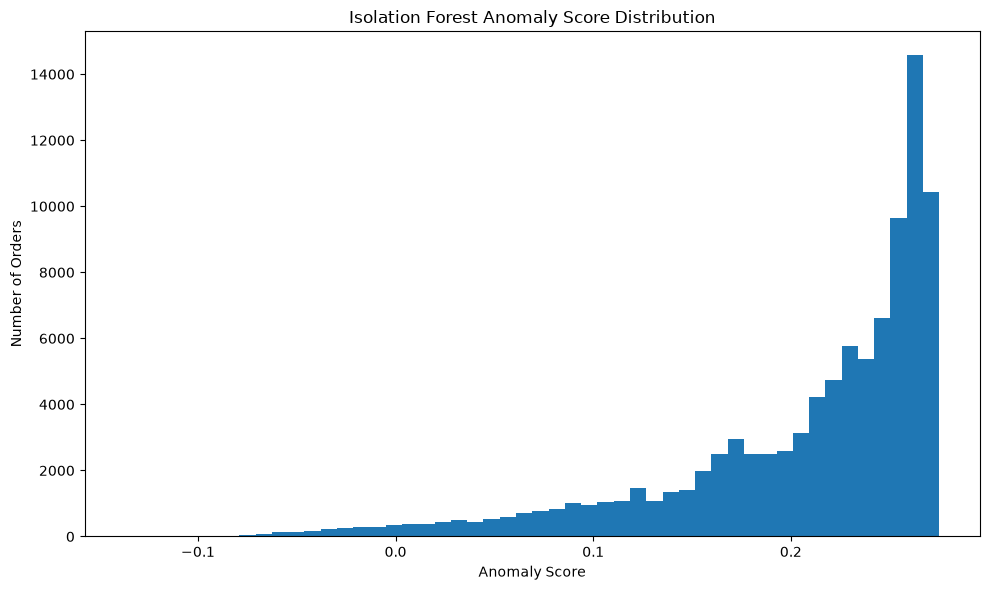

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    anomaly_output["anomaly_score"],
    bins=50
)

plt.title("Isolation Forest Anomaly Score Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Orders")

plt.tight_layout()

plt.savefig(
    Chart_Path
    / "27_anomaly_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

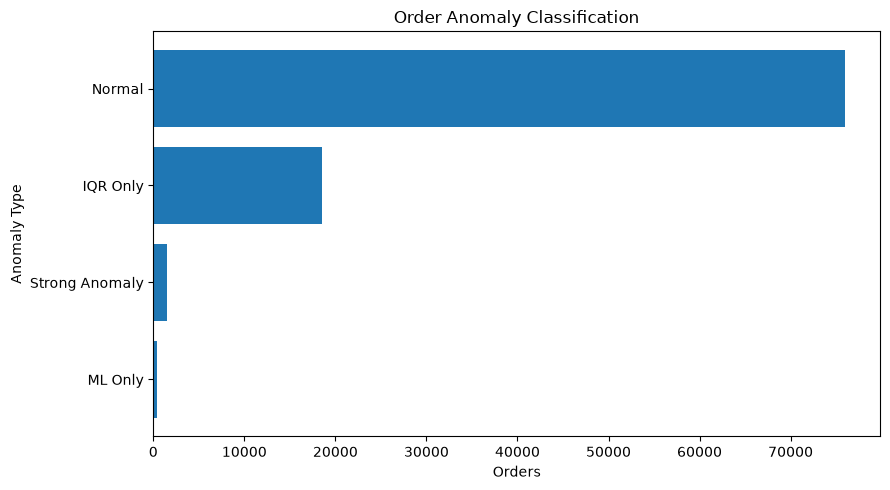

In [27]:
#Anomaly count chart
plot_data = (
    anomaly_type_summary
    .sort_values("orders")
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data["anomaly_type"],
    plot_data["orders"]
)

plt.title("Order Anomaly Classification")
plt.xlabel("Orders")
plt.ylabel("Anomaly Type")

plt.tight_layout()

plt.savefig(
    Chart_Path
    / "28_order_anomaly_classification.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
print("Total orders analyzed:", len(anomaly_output))

print("\nAnomaly types:")
print(
    anomaly_output["anomaly_type"]
    .value_counts()
)

print("\nIQR anomaly rate:",
      round(
          anomaly_output["iqr_anomaly"].mean() * 100,
          2
      ),
      "%")

print(
    "Isolation Forest anomaly rate:",
    round(
        anomaly_output["isolation_anomaly"].mean() * 100,
        2
    ),
    "%"
)

print("\nTop anomalies:")
print(
    top_anomalies[
        [
            "order_id",
            "total_revenue",
            "total_freight",
            "item_count",
            "anomaly_score",
            "anomaly_type"
        ]
    ].head(10)
)

Total orders analyzed: 96461

Anomaly types:
anomaly_type
Normal            76020
IQR Only          18511
Strong Anomaly     1516
ML Only             414
Name: count, dtype: int64

IQR anomaly rate: 20.76 %
Isolation Forest anomaly rate: 2.0 %

Top anomalies:
                               order_id  total_revenue  total_freight  \
49021  8272b63d03f5f79c56e9e4120aec44ef          31.80         164.37   
65935  af822dacd6f5cff7376413c03a388bb7          61.26         182.76   
1432   03caa2c082116e1d31e67e9ae3700499       13440.00         224.08   
56106  95d6357ffe41aa6d2998852a710c70a0          17.50          91.15   
23848  3f744e5030fb02e02651eb31d5204878          35.40         109.38   
74039  c471a28c25283860362c67c0a1cd1694          28.68          94.74   
22841  3caf6c286c8cde37ea9c0fb2da0e3169          47.40         132.36   
36924  6232b520aa859c47ba46e5213737f418          19.50          76.15   
87915  e928cc82f61f2dcab3ad58d6e7200224          60.00         124.80   
30587  50f

In [29]:
print("Orders in orders_clean:", orders["order_id"].nunique())
print("Orders in anomaly dataset:", order_features["order_id"].nunique())

missing_status = order_features["order_status"].isna().sum()

print("Missing order status:", missing_status)

Orders in orders_clean: 96461
Orders in anomaly dataset: 96461
Missing order status: 0
